In [117]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import os 
import numpy as np
import pandas as pd

In [118]:
for dirname, _, filenames in os.walk('kaggle'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

kaggle/SPY_2018.csv
kaggle/NVDA.csv
kaggle/orcl-1995-2014.txt
kaggle/TSLA.csv
kaggle/SPY.csv
kaggle/VIX.csv
kaggle/SPY_VIX.csv


In [119]:
# ok now we learnt how to distributing the data 

# we define as a function here 
def plotPerColumnnDistribution (df, nGraphShown, nGraphPerRow): 
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]]
    # this is for the display purposing so it set as in between 1 to 50 
    nRow, nCol = df.shape
    
    ## for the shape, it is mean how is the dimension of the data

    columnsName = list(df)
    nGraphRow = (nCol + nGraphPerRow - 1) / nGraphPerRow
    plt.figure(
        num = None, figsize = (6 * nGraphPerRow, 8 * nGraphRow),
        dpi = 80, facecolor = 'w', edgecolor = 'k'
    )
    for i in range(min(nCol, nGraphShown)):
        plt.subplot(nGraphRow, nGraphPerRow, i + 1)
        columnDf = df.iloc[:, i]
        if (not np.issudbtype(type(columnDf.iloc[0]), np.number)):
            valueCounts = columnDf.value_counts()
            valueCounts.plot.bar()
        else :
            columnDf.hist()
        plt.ylabel('counts')
        plt.xticks(rotation = 90)
        plt.title(f'{columnsName[i]} (column {i})')
    plt.tight_layout(pad = 1.0, w_pad = 1.0, h_pad = 1.0) 
    plt.show()
            


In [120]:
# Correlation matrix
def plotCorrelationMatrix(df, graphWidth):
    filename = df.dataframeName
    df = df.dropna(axis='columns') # drop columns with NaN

    # Convert datetime-like columns to numeric
    for col in df.columns:
        if df[col].dtype == 'object':
            try:
                temp = pd.to_datetime(df[col], errors='raise')
                df[col] = temp.astype('int64') // 10**9   # seconds since epoch
            except:
                pass    # keep as is if it's not a datetime


    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    
    if df.shape[1] < 2:
        print(f'No correlation plots shown: The number of non-NaN or constant columns ({df.shape[1]}) is less than 2')
        return
    
    corr = df.corr()
    plt.figure(num=None, figsize=(graphWidth, graphWidth), dpi=80, facecolor='w', edgecolor='k')
    corrMat = plt.matshow(corr, fignum = 1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.gca().xaxis.tick_bottom()
    plt.colorbar(corrMat)
    plt.title(f'Correlation Matrix for {filename}', fontsize=15)
    plt.show()

In [121]:
# Scatter and density plots
def plotScatterMatrix(df, plotSize, textSize):
    df = df.select_dtypes(include =[np.number]) # keep only numerical columns
    # Remove rows and columns that would lead to df being singular
    df = df.dropna(axis = 'columns')
    df = df[[col for col in df if df[col].nunique() > 1]] # keep columns where there are more than 1 unique values
    columnNames = list(df)
    if len(columnNames) > 10: # reduce the number of columns for matrix inversion of kernel density plots
        columnNames = columnNames[:10]
    df = df[columnNames]
    ax = pd.plotting.scatter_matrix(df, alpha=0.75, figsize=[plotSize, plotSize], diagonal='kde')
    corrs = df.corr().values
    for i, j in zip(*plt.np.triu_indices_from(ax, k = 1)):
        ax[i, j].annotate('Corr. coef = %.3f' % corrs[i, j], (0.8, 0.2), xycoords='axes fraction', ha='center', va='center', size=textSize)
    plt.suptitle('Scatter and Density Plot')
    plt.show()

In [122]:
nRowsRead = 1000 

df1 = pd.read_csv('kaggle/NVDA.csv', delimiter=',', nrows= nRowsRead)
df1.dataframeName = 'NVDA.csv'
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 6 columns


In [123]:
df1.dtypes

timestamp     object
open         float64
high         float64
low          float64
close        float64
volume         int64
dtype: object

In [124]:
df1.head

<bound method NDFrame.head of                timestamp      open      high      low     close  volume
0    2020-03-23 09:31:00  204.1600  204.1600  204.160  204.1600  568408
1    2020-03-23 09:32:00  204.3191  204.5065  200.560  200.7100   81709
2    2020-03-23 09:33:00  200.7299  206.1234  200.690  205.3801   59476
3    2020-03-23 09:34:00  205.4900  208.4999  204.120  207.7100   69771
4    2020-03-23 09:35:00  205.8200  205.8200  205.820  205.8200   57105
..                   ...       ...       ...      ...       ...     ...
995  2020-03-25 13:12:00  257.0700  257.6000  257.000  257.5000   27545
996  2020-03-25 13:13:00  257.6000  258.2700  257.568  257.8490   52156
997  2020-03-25 13:14:00  257.7300  257.7825  256.870  257.3900   28812
998  2020-03-25 13:15:00  257.3300  257.6227  257.100  257.6227   20001
999  2020-03-25 13:16:00  257.5600  258.3400  257.550  258.0600   35535

[1000 rows x 6 columns]>

In [125]:
plotPerColumnnDistribution(df1, 10, 5)

<Figure size 2400x512 with 0 Axes>

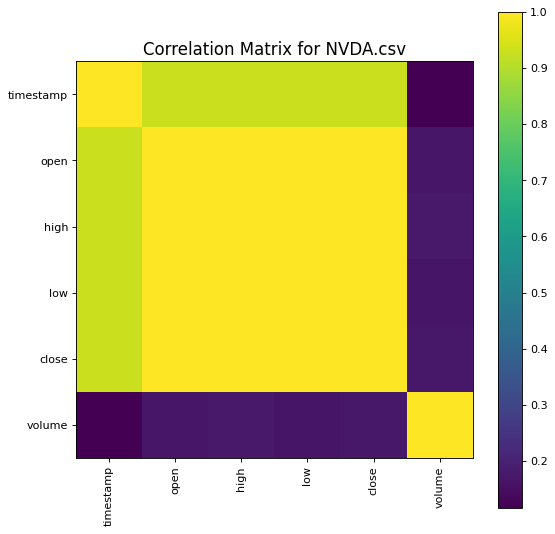

In [126]:
plotCorrelationMatrix(df1, 8)

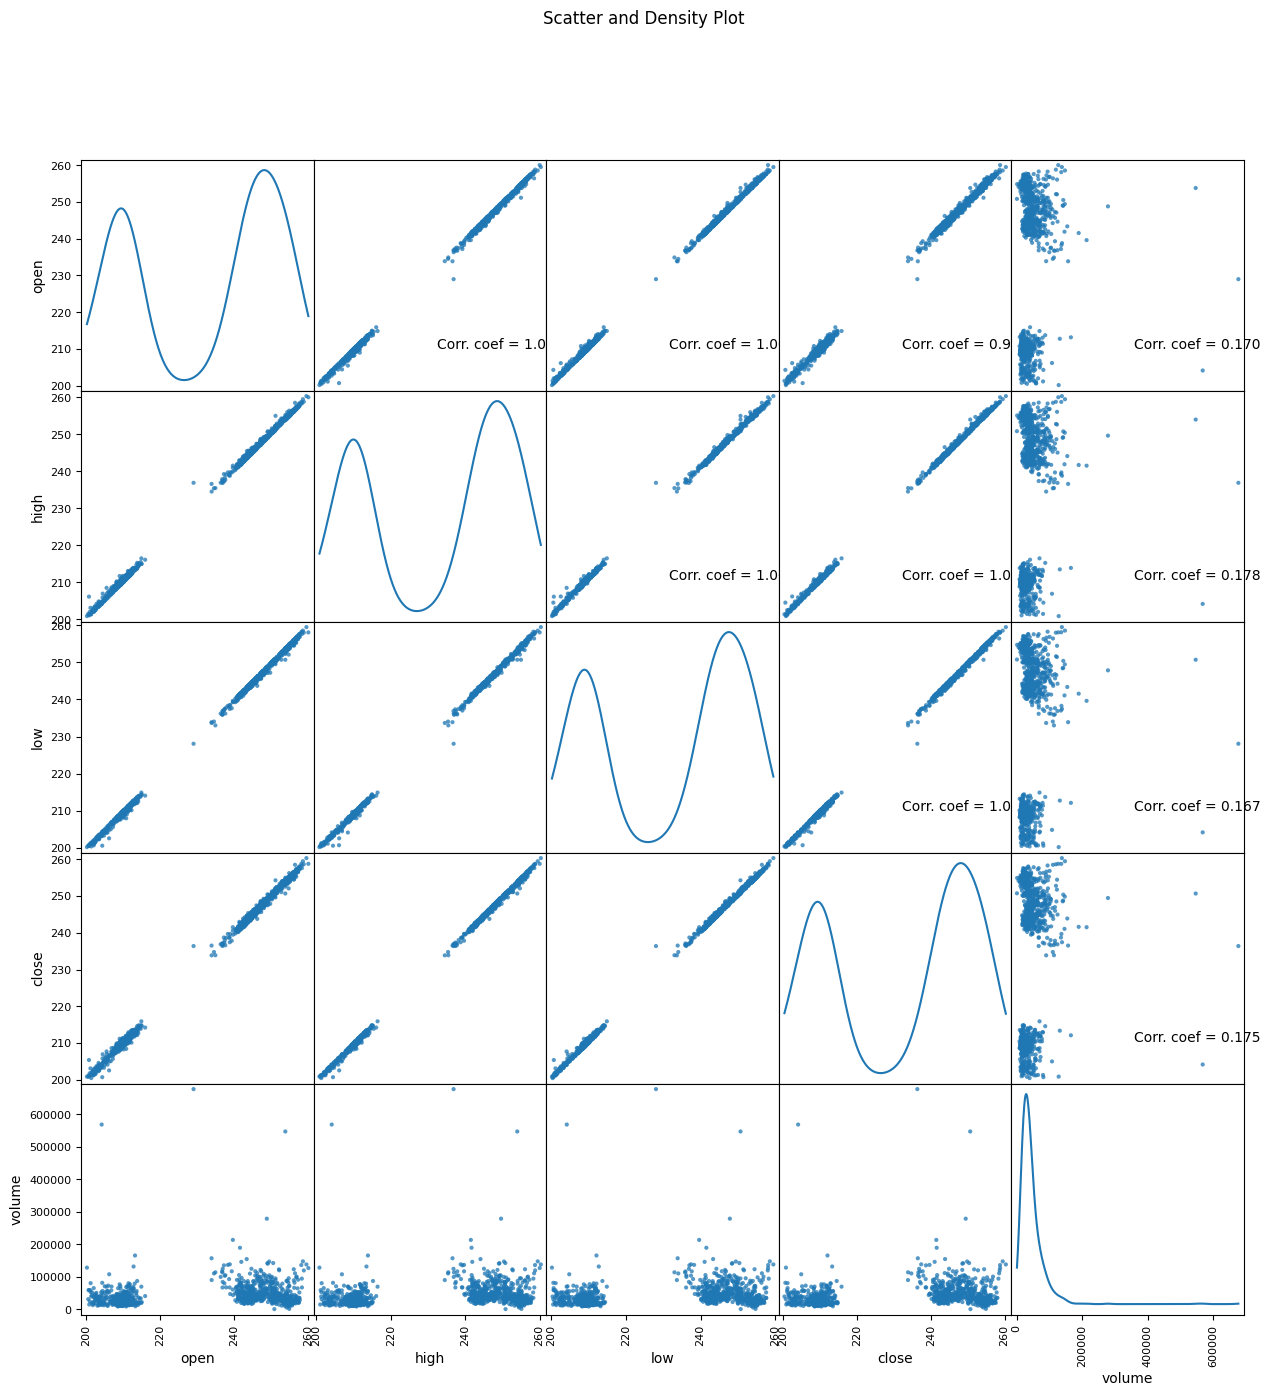

In [127]:
plotScatterMatrix( df1, 15 , 10 )

In [128]:
nRowsRead = 1000 # specify 'None' if want to read whole file
# SPY.csv may have more rows in reality, but we are only loading/previewing the first 1000 rows
df2 = pd.read_csv('kaggle/SPY.csv', delimiter=',', nrows = nRowsRead)
df2.dataframeName = 'SPY.csv'
nRow, nCol = df2.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 1000 rows and 7 columns


In [129]:
df2.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-03,148.25000,148.25000,143.875000,145.4375,99.978989,8164300
1,2000-01-04,143.53125,144.06250,139.640625,139.7500,96.069160,8089800
2,2000-01-05,139.93750,141.53125,137.250000,140.0000,96.241058,12177900
3,2000-01-06,139.62500,141.50000,137.750000,137.7500,94.694298,6227200
4,2000-01-07,140.31250,145.75000,140.062500,145.7500,100.193771,8066500


In [130]:
plotPerColumnnDistribution(df2, 10, 5)

<Figure size 2400x512 with 0 Axes>

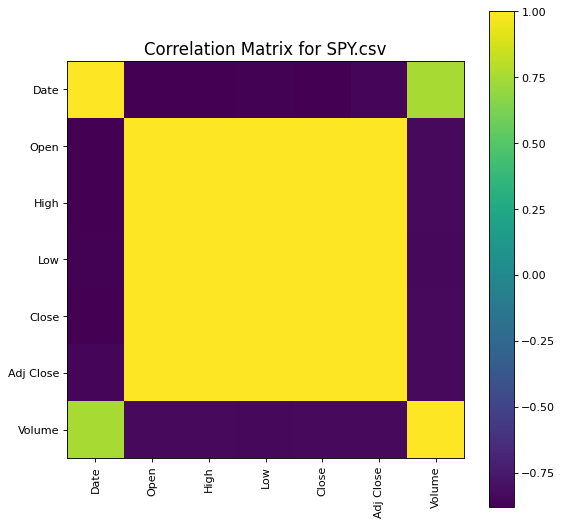

In [131]:
plotCorrelationMatrix( df2, 8)

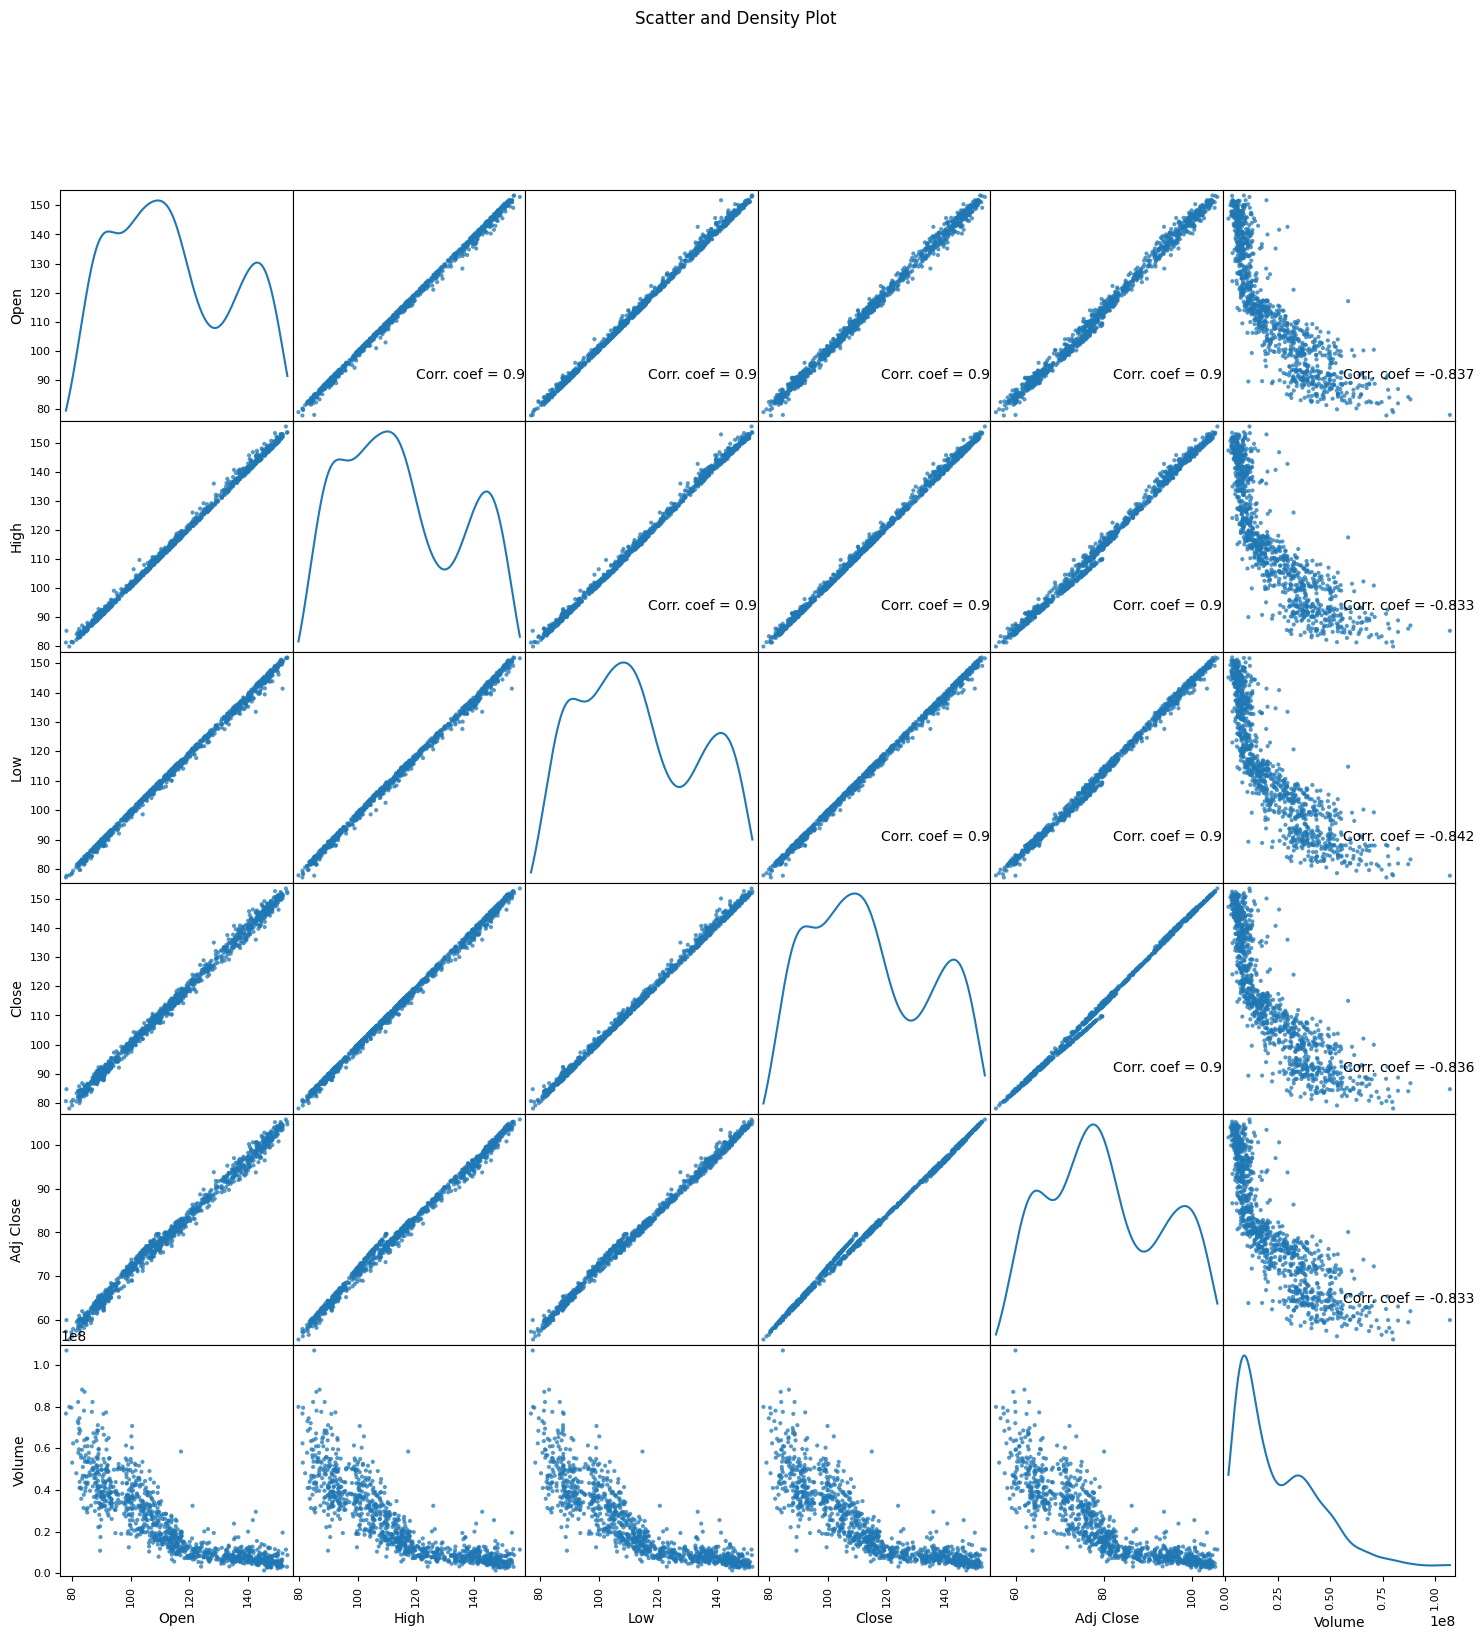

In [132]:
plotScatterMatrix(df2, 18, 10)

In [133]:
nRowsRead = 1000 # specify 'None' if want to read whole file
# SPY_2018.csv may have more rows in reality, but we are only loading/previewing the first 1000 rows
df3 = pd.read_csv('kaggle/SPY_2018.csv', delimiter=',', nrows = nRowsRead)
df3.dataframeName = 'SPY_2018.csv'
nRow, nCol = df3.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 534 rows and 7 columns


<Figure size 2400x512 with 0 Axes>

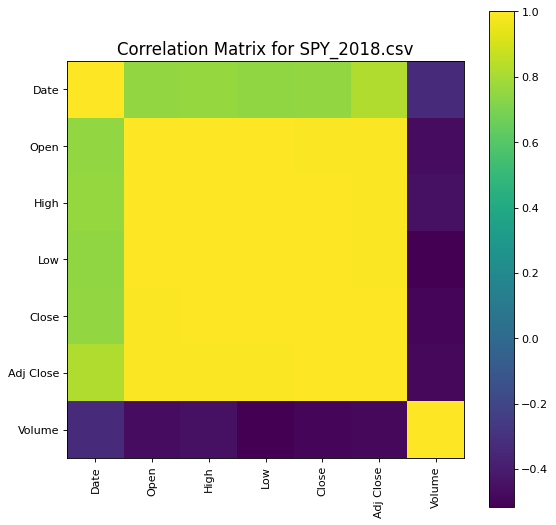

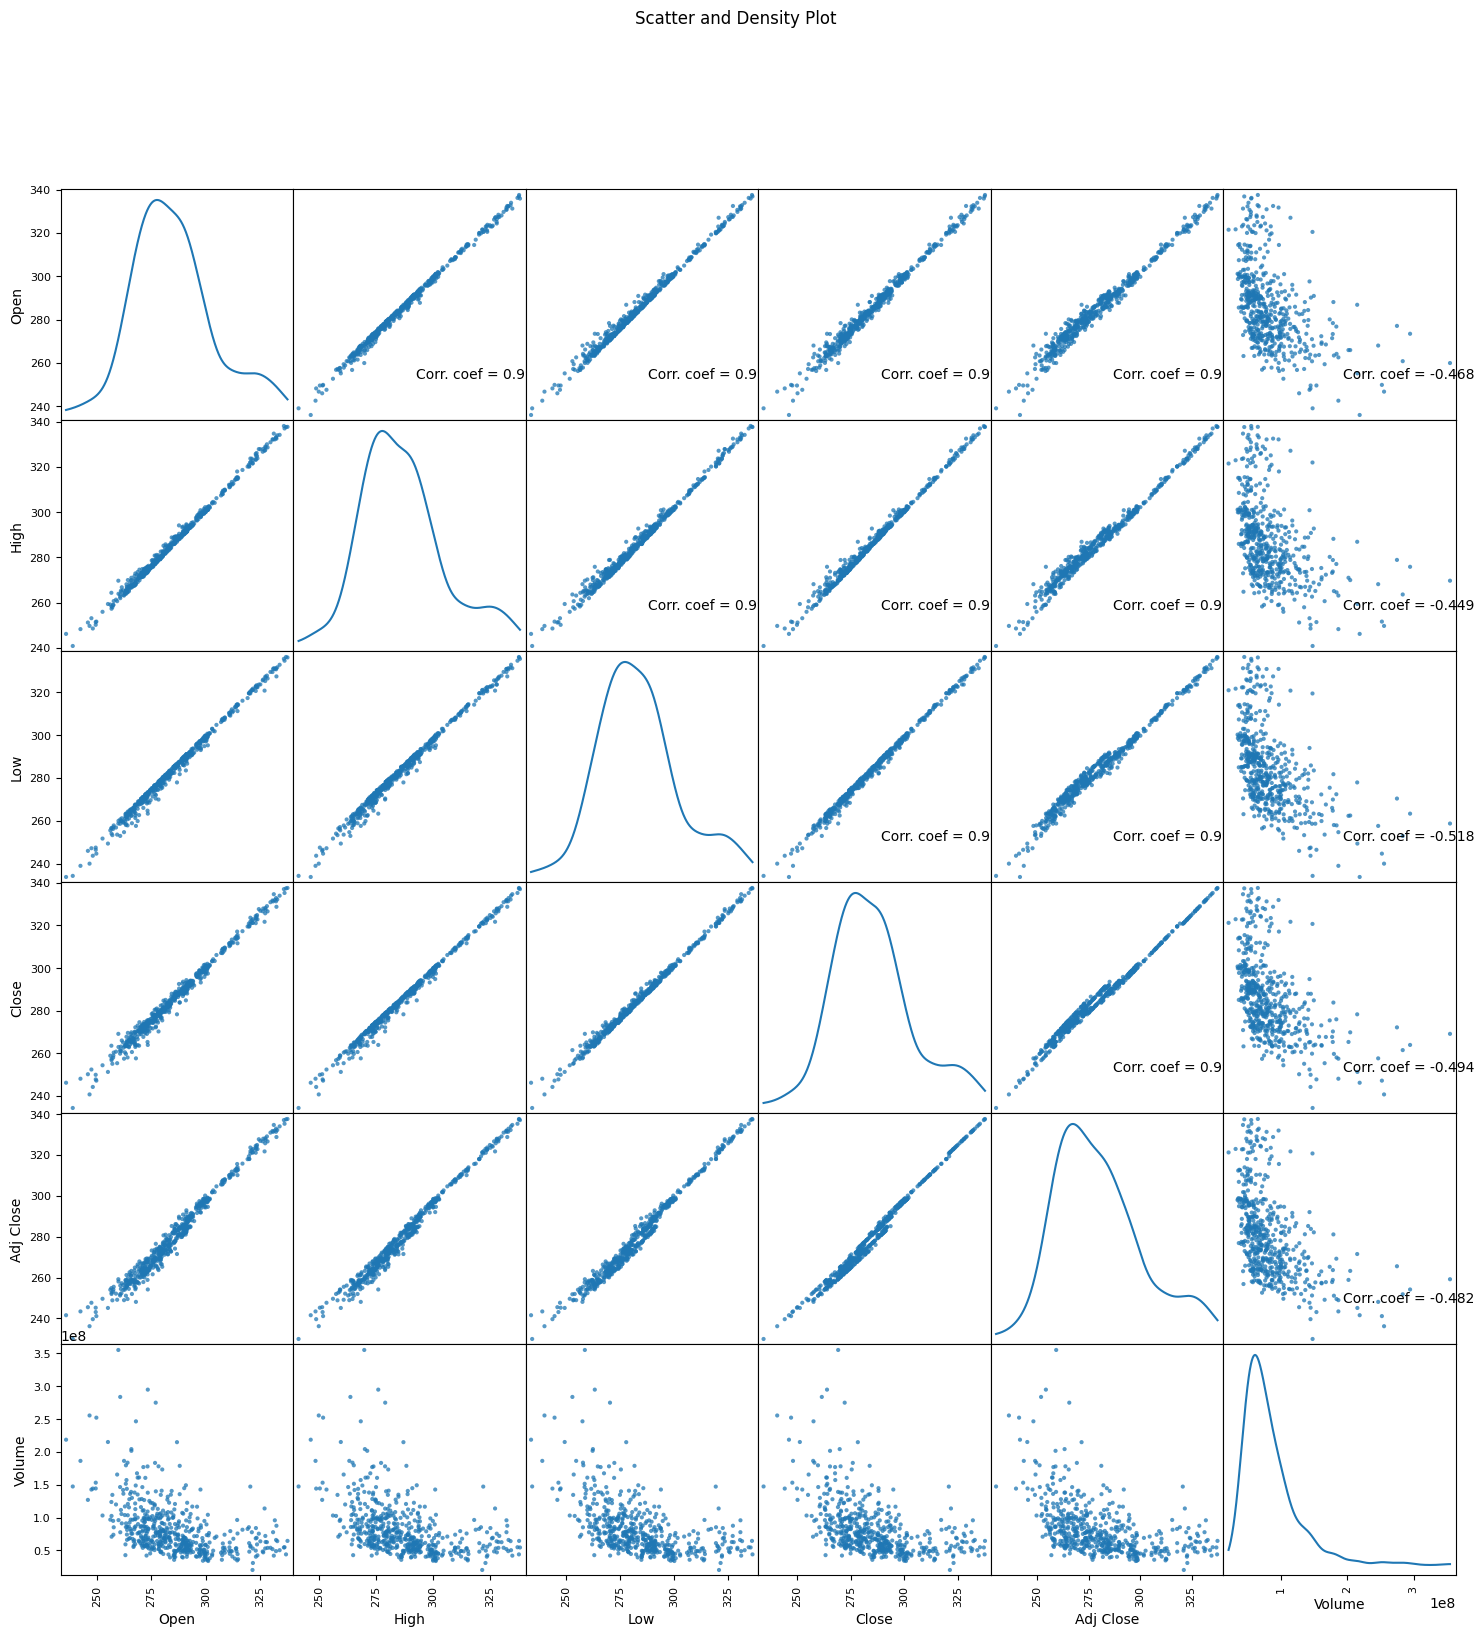

In [134]:
df3.head()

plotPerColumnnDistribution(df3, 10 , 5)

plotCorrelationMatrix(df3, 8)

plotScatterMatrix(df3,18, 10)

